In [2]:
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image
from IPython.display import display

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as T
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


def find_project_root(start):
    for path in [start, *start.parents]:
        if (path / "Data").is_dir() and (path / "reports" / "clean_manifest.csv").is_file():
            return path
    raise FileNotFoundError("Could not find project root containing Data/ and reports/clean_manifest.csv")

ROOT = find_project_root(Path.cwd())
DATA_DIR = ROOT / "Data"
MANIFEST_PATH = ROOT / "reports" / "clean_manifest.csv"
MODEL_DIR = ROOT / "models"
REPORT_DIR = ROOT / "reports"
MODEL_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)

CLASSES = [
    "adenocarcinoma",
    "large.cell.carcinoma",
    "normal",
    "squamous.cell.carcinoma"
]
DISPLAY_NAMES = [
    "Adenocarcinoma",
    "Large Cell Carcinoma",
    "Normal",
    "Squamous Cell Carcinoma"
]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASSES)}

IMAGE_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 25
PATIENCE = 7
BACKBONE_LR = 1e-5
CLASSIFIER_LR = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Cancaria ML Experiment")
print("-" * 35)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Project:", ROOT)
print("Manifest exists:", MANIFEST_PATH.exists())

Cancaria ML Experiment
-----------------------------------
PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
Project: d:\Projects\Cancaria
Manifest exists: True


In [3]:
manifest = pd.read_csv(MANIFEST_PATH)
required_columns = {"split", "label", "path", "sha256", "include"}
missing = required_columns - set(manifest.columns)
if missing:
    raise ValueError(f"Manifest is missing columns: {sorted(missing)}")

included = manifest[manifest["include"].astype(str).str.lower().eq("true")].copy()
included = included[included["split"].isin(["train", "valid", "test"])]

if included["sha256"].duplicated().any():
    raise ValueError("Duplicate SHA-256 hashes remain among included images.")

included["label"] = included["label"].astype(str)
included["label_idx"] = included["label"].map(CLASS_TO_IDX)
if included["label_idx"].isna().any():
    raise ValueError("Unknown labels found in manifest.")
included["label_idx"] = included["label_idx"].astype(int)
included["full_path"] = included["path"].map(lambda p: ROOT / Path(p))

missing_files = included.loc[~included["full_path"].map(Path.is_file), "path"].tolist()
if missing_files:
    raise FileNotFoundError(f"Missing files in manifest, first few: {missing_files[:5]}")

train_df = included[included["split"] == "train"].reset_index(drop=True)
valid_df = included[included["split"] == "valid"].reset_index(drop=True)
test_df = included[included["split"] == "test"].reset_index(drop=True)

for split_name, frame in [("train", train_df), ("valid", valid_df), ("test", test_df)]:
    if frame.empty:
        raise ValueError(f"No included records in {split_name} split.")
    print(f"{split_name}: {len(frame)} images")

print("Total included:", len(included))
display(included.groupby(["split", "label"]).size().unstack(fill_value=0).reindex(index=["train", "valid", "test"], columns=CLASSES, fill_value=0))

train: 493 images
valid: 65 images
test: 288 images
Total included: 846


label,adenocarcinoma,large.cell.carcinoma,normal,squamous.cell.carcinoma
split,,,,
train,194,114,33,152
valid,23,21,6,15
test,120,51,27,90


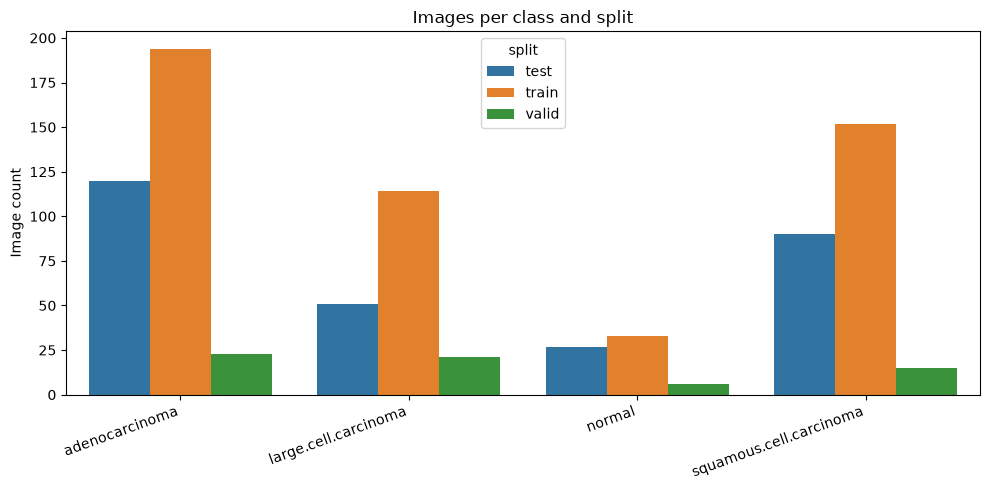

Training class counts:
label
adenocarcinoma             194
large.cell.carcinoma       114
normal                      33
squamous.cell.carcinoma    152
Name: count, dtype: int64

Validation has only six Normal images in this cleaned split, so validation metrics for that class will be unstable.


In [4]:
distribution = (
    included.groupby(["split", "label"]).size()
    .rename("images").reset_index()
)

plt.figure(figsize=(10, 5))
sns.barplot(data=distribution, x="label", y="images", hue="split", order=CLASSES)
plt.title("Images per class and split")
plt.xlabel("")
plt.ylabel("Image count")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

print("Training class counts:")
print(train_df["label"].value_counts().reindex(CLASSES, fill_value=0))
print("\nValidation has only six Normal images in this cleaned split, so validation metrics for that class will be unstable.")

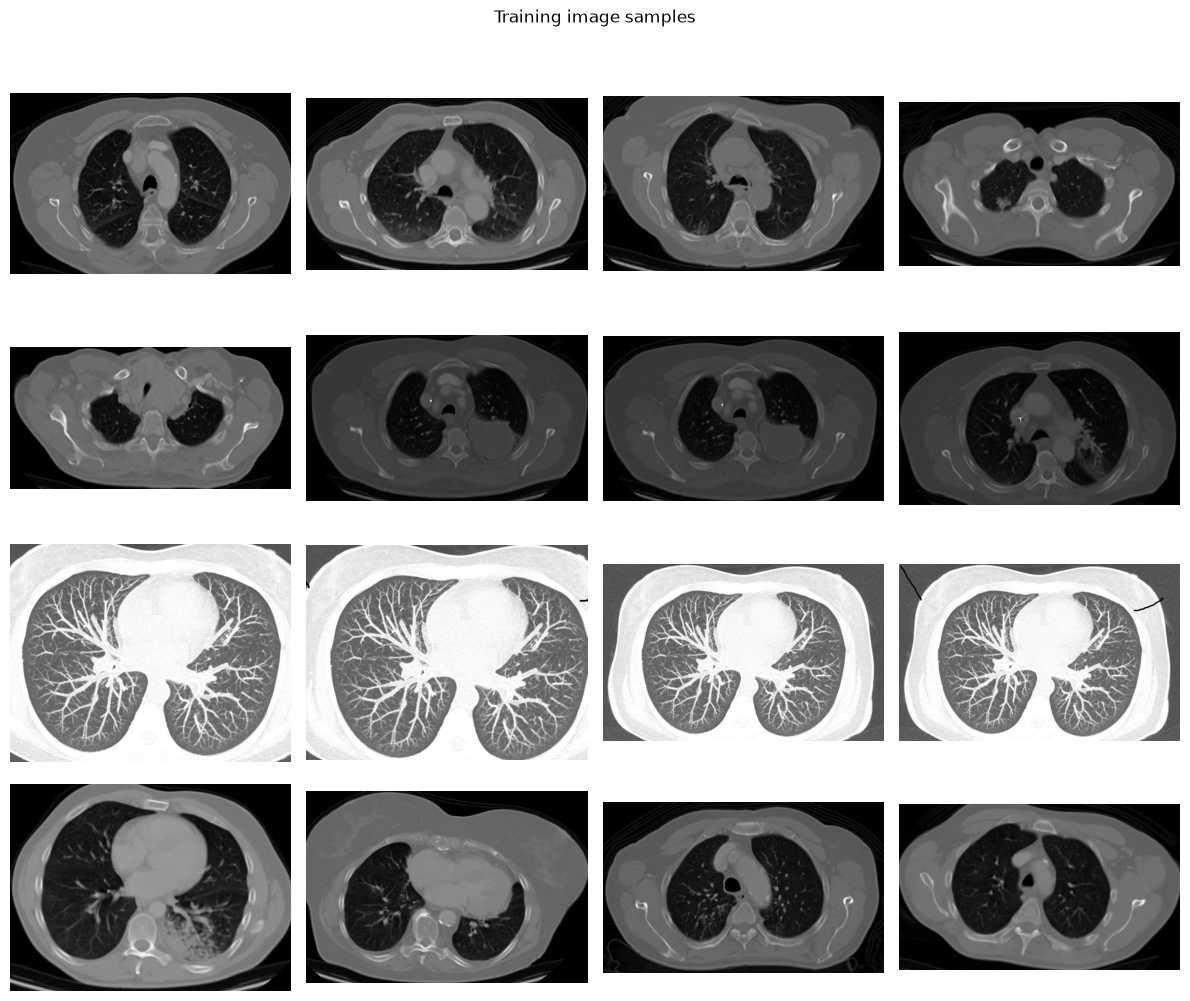

In [5]:
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(12, 10))
for row, label in enumerate(CLASSES):
    samples = train_df[train_df["label"] == label].head(4)
    for col in range(4):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(samples):
            image_path = samples.iloc[col]["full_path"]
            with Image.open(image_path) as image:
                ax.imshow(image.convert("RGB"))
            if col == 0:
                ax.set_ylabel(DISPLAY_NAMES[row], fontsize=9)
plt.suptitle("Training image samples", y=1.01)
plt.tight_layout()
plt.show()

In [6]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = T.Compose([
    T.Resize(256),
    T.RandomCrop(IMAGE_SIZE),
    T.RandomRotation(5, interpolation=T.InterpolationMode.BILINEAR),
    T.ToTensor(),
    T.Normalize(mean=MEAN, std=STD)
])

eval_transform = T.Compose([
    T.Resize(256),
    T.CenterCrop(IMAGE_SIZE),
    T.ToTensor(),
    T.Normalize(mean=MEAN, std=STD)
])

print("Transforms ready.")

Transforms ready.


In [7]:
class LungCTDataset(Dataset):
    def __init__(self, frame, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row["full_path"]) as image:
            image = image.convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, int(row["label_idx"])

train_dataset = LungCTDataset(train_df, train_transform)
valid_dataset = LungCTDataset(valid_df, eval_transform)
test_dataset = LungCTDataset(test_df, eval_transform)

loader_options = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda"
}

train_loader = DataLoader(train_dataset, shuffle=True, **loader_options)
valid_loader = DataLoader(valid_dataset, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)

images, labels = next(iter(train_loader))
print("Batch images:", images.shape)
print("Batch labels:", labels.shape)
print("Image tensor device before transfer:", images.device)

Batch images: torch.Size([16, 3, 224, 224])
Batch labels: torch.Size([16])
Image tensor device before transfer: cpu


In [10]:
class_counts = np.bincount(train_df["label_idx"].to_numpy(), minlength=len(CLASSES))
if np.any(class_counts == 0):
    raise ValueError("At least one class has no training examples.")

class_weights = len(train_df) / (len(CLASSES) * class_counts)
class_weights = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)

for name, count, weight in zip(DISPLAY_NAMES, class_counts, class_weights.cpu().numpy()):
    print(f"{name:25s} count={count:3d} weight={weight:.3f}")

Adenocarcinoma            count=194 weight=0.635
Large Cell Carcinoma      count=114 weight=1.081
Normal                    count= 33 weight=3.735
Squamous Cell Carcinoma   count=152 weight=0.811


In [11]:
optimizer = optim.AdamW(
    [
        {
            "params": (
                list(model.conv1.parameters())
                + list(model.bn1.parameters())
                + list(model.layer1.parameters())
                + list(model.layer2.parameters())
                + list(model.layer3.parameters())
                + list(model.layer4.parameters())
            ),
            "lr": BACKBONE_LR
        },
        {
            "params": model.fc.parameters(),
            "lr": CLASSIFIER_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

print("Optimizer: AdamW")
print("Backbone LR:", BACKBONE_LR)
print("Classifier LR:", CLASSIFIER_LR)
print("Weight Decay:", WEIGHT_DECAY)
print("Scheduler: ReduceLROnPlateau")
print("Loss: Weighted Cross Entropy")

Optimizer: AdamW
Backbone LR: 1e-05
Classifier LR: 0.0001
Weight Decay: 0.0001
Scheduler: ReduceLROnPlateau
Loss: Weighted Cross Entropy


In [12]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss = 0.0
    total_samples = 0
    all_labels = []
    all_predictions = []

    for batch_images, batch_labels in loader:
        batch_images = batch_images.to(DEVICE, non_blocking=True)
        batch_labels = batch_labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(batch_images)
            loss = criterion(logits, batch_labels)
            if training:
                loss.backward()
                optimizer.step()

        batch_size = batch_labels.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size
        predictions = logits.argmax(dim=1)
        all_labels.extend(batch_labels.detach().cpu().numpy())
        all_predictions.extend(predictions.detach().cpu().numpy())

    return {
        "loss": total_loss / total_samples,
        "accuracy": accuracy_score(all_labels, all_predictions),
        "macro_f1": f1_score(
            all_labels, all_predictions,
            labels=list(range(len(CLASSES))),
            average="macro", zero_division=0
        )
    }

In [13]:
history = {
    "train_loss": [], "valid_loss": [],
    "train_accuracy": [], "valid_accuracy": [],
    "train_macro_f1": [], "valid_macro_f1": []
}

checkpoint_path = MODEL_DIR / "cancaria_resnet18_best.pth"
best_f1 = -1.0
best_val_loss = float("inf")
wait = 0

for epoch in range(EPOCHS):
    train_metrics = run_epoch(model, train_loader, criterion, optimizer)
    valid_metrics = run_epoch(model, valid_loader, criterion)
    scheduler.step(valid_metrics["macro_f1"])

    for key, value in [
        ("train_loss", train_metrics["loss"]),
        ("valid_loss", valid_metrics["loss"]),
        ("train_accuracy", train_metrics["accuracy"]),
        ("valid_accuracy", valid_metrics["accuracy"]),
        ("train_macro_f1", train_metrics["macro_f1"]),
        ("valid_macro_f1", valid_metrics["macro_f1"])
    ]:
        history[key].append(float(value))

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"train loss {train_metrics['loss']:.4f} | "
        f"train acc {train_metrics['accuracy']:.3f} | "
        f"train F1 {train_metrics['macro_f1']:.3f} | "
        f"valid loss {valid_metrics['loss']:.4f} | "
        f"valid acc {valid_metrics['accuracy']:.3f} | "
        f"valid F1 {valid_metrics['macro_f1']:.3f}"
    )

    improved = (
        valid_metrics["macro_f1"] > best_f1 or
        (valid_metrics["macro_f1"] == best_f1 and valid_metrics["loss"] < best_val_loss)
    )

    if improved:
        best_f1 = valid_metrics["macro_f1"]
        best_val_loss = valid_metrics["loss"]
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        torch.save({
            "model_state_dict": best_state,
            "classes": CLASSES,
            "display_names": DISPLAY_NAMES,
            "image_size": IMAGE_SIZE,
            "mean": MEAN,
            "std": STD,
            "architecture": "resnet18",
            "best_validation_macro_f1": best_f1,
            "best_validation_loss": best_val_loss
        }, checkpoint_path)
        wait = 0
        print("  Saved best checkpoint.")
    else:
        wait += 1

    if wait >= PATIENCE:
        print("Early stopping.")
        break

checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print(f"\nBest validation macro F1: {checkpoint['best_validation_macro_f1']:.3f}")
print("Checkpoint:", checkpoint_path)

Epoch 01/25 | train loss 1.4565 | train acc 0.298 | train F1 0.290 | valid loss 1.3722 | valid acc 0.215 | valid F1 0.320
  Saved best checkpoint.
Epoch 02/25 | train loss 1.2297 | train acc 0.383 | train F1 0.396 | valid loss 1.2095 | valid acc 0.415 | valid F1 0.481
  Saved best checkpoint.
Epoch 03/25 | train loss 1.1467 | train acc 0.460 | train F1 0.476 | valid loss 1.1514 | valid acc 0.446 | valid F1 0.542
  Saved best checkpoint.
Epoch 04/25 | train loss 1.0145 | train acc 0.519 | train F1 0.534 | valid loss 1.0758 | valid acc 0.554 | valid F1 0.617
  Saved best checkpoint.
Epoch 05/25 | train loss 1.0175 | train acc 0.548 | train F1 0.577 | valid loss 1.0663 | valid acc 0.523 | valid F1 0.606
Epoch 06/25 | train loss 1.0232 | train acc 0.566 | train F1 0.574 | valid loss 1.0566 | valid acc 0.600 | valid F1 0.671
  Saved best checkpoint.
Epoch 07/25 | train loss 0.9590 | train acc 0.600 | train F1 0.622 | valid loss 1.0425 | valid acc 0.646 | valid F1 0.708
  Saved best checkpoi

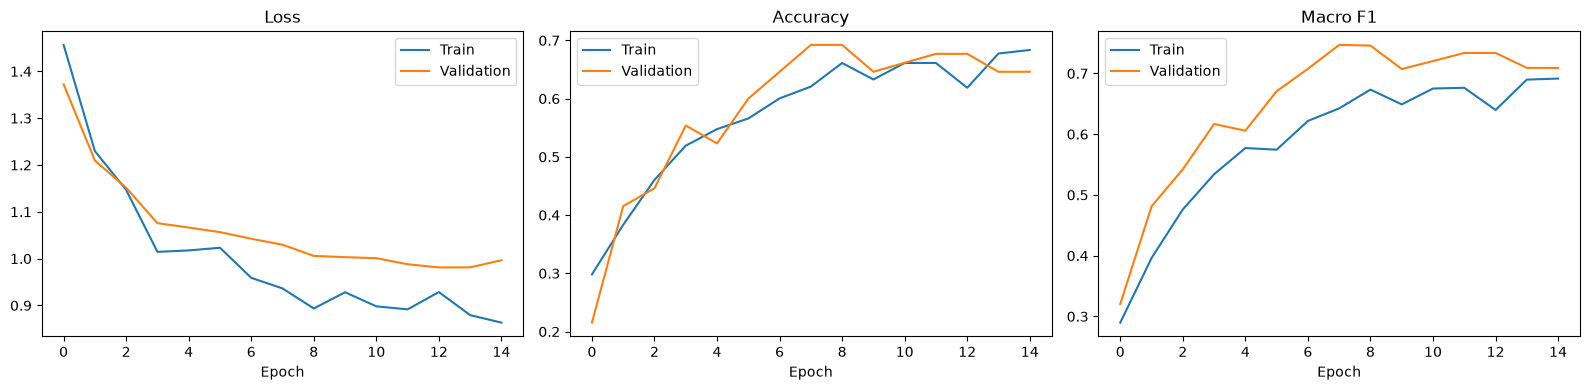

In [14]:
history_df = pd.DataFrame(history)
history_df.to_csv(REPORT_DIR / "training_history.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(history_df["train_loss"], label="Train")
axes[0].plot(history_df["valid_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_df["train_accuracy"], label="Train")
axes[1].plot(history_df["valid_accuracy"], label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

axes[2].plot(history_df["train_macro_f1"], label="Train")
axes[2].plot(history_df["valid_macro_f1"], label="Validation")
axes[2].set_title("Macro F1")
axes[2].set_xlabel("Epoch")
axes[2].legend()

plt.tight_layout()
plt.savefig(REPORT_DIR / "training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

In [15]:
model.eval()
y_true = []
y_pred = []
y_prob = []

with torch.inference_mode():
    for batch_images, batch_labels in test_loader:
        batch_images = batch_images.to(DEVICE, non_blocking=True)
        logits = model(batch_images)
        probabilities = torch.softmax(logits, dim=1)
        predictions = probabilities.argmax(dim=1)

        y_true.extend(batch_labels.numpy().tolist())
        y_pred.extend(predictions.cpu().numpy().tolist())
        y_prob.extend(probabilities.cpu().numpy().tolist())

y_prob = np.asarray(y_prob)

metrics = {
    "test_images": len(y_true),
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
    "macro_f1": float(f1_score(
        y_true, y_pred, labels=list(range(len(CLASSES))),
        average="macro", zero_division=0
    ))
}

print(json.dumps(metrics, indent=2))
report = classification_report(
    y_true, y_pred,
    labels=list(range(len(CLASSES))),
    target_names=DISPLAY_NAMES,
    zero_division=0,
    output_dict=True
)
display(pd.DataFrame(report).T)

with open(REPORT_DIR / "test_metrics.json", "w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)

with open(REPORT_DIR / "classification_report.json", "w", encoding="utf-8") as file:
    json.dump(report, file, indent=2)

{
  "test_images": 288,
  "accuracy": 0.625,
  "balanced_accuracy": 0.6353349673202614,
  "macro_f1": 0.6276021630912678
}


,precision,recall,f1-score,support
Adenocarcinoma,0.575419,0.858333,0.688963,120.000
Large Cell Carcinoma,0.681818,0.294118,0.410959,51.000
Normal,0.870968,1.000000,0.931034,27.000
Squamous Cell Carcinoma,0.625000,0.388889,0.479452,90.000
accuracy,0.625000,0.625000,0.625000,0.625
macro avg,0.688301,0.635335,0.627602,288.000
weighted avg,0.637462,0.625000,0.596955,288.000


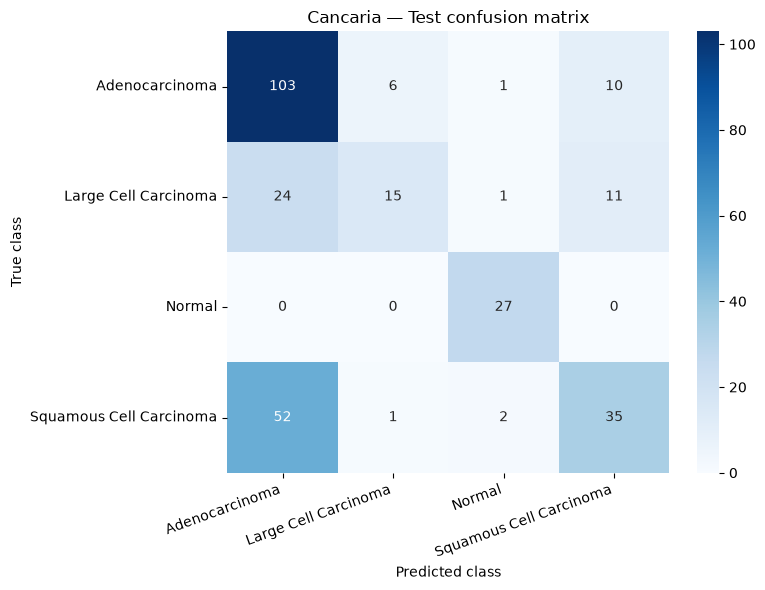

,path,label,predicted_label,correct,score_adenocarcinoma,score_large.cell.carcinoma,score_normal,score_squamous.cell.carcinoma,cancer_class_score_sum_uncalibrated
0,Data/test/adenocarcinoma/000108 (3).png,adenocarcinoma,squamous.cell.carcinoma,False,0.398817,0.055432,0.101456,0.444294,0.898544
1,Data/test/adenocarcinoma/000109 (2).png,adenocarcinoma,adenocarcinoma,True,0.502622,0.171993,0.062128,0.263256,0.937872
2,Data/test/adenocarcinoma/000109 (4).png,adenocarcinoma,adenocarcinoma,True,0.509045,0.209498,0.157107,0.124350,0.842893
3,Data/test/adenocarcinoma/000109 (5).png,adenocarcinoma,adenocarcinoma,True,0.397326,0.195487,0.124763,0.282423,0.875237
4,Data/test/adenocarcinoma/000112 (2).png,adenocarcinoma,adenocarcinoma,True,0.583408,0.155409,0.136400,0.124783,0.863600
5,Data/test/adenocarcinoma/000113 (7).png,adenocarcinoma,adenocarcinoma,True,0.470190,0.215728,0.193632,0.120450,0.806368
6,Data/test/adenocarcinoma/000114 (5).png,adenocarcinoma,adenocarcinoma,True,0.528784,0.106557,0.146475,0.218184,0.853525
7,Data/test/adenocarcinoma/000114.png,adenocarcinoma,adenocarcinoma,True,0.574147,0.161979,0.128761,0.135112,0.871239
8,Data/test/adenocarcinoma/000115 (4).png,adenocarcinoma,adenocarcinoma,True,0.530685,0.143365,0.090348,0.235602,0.909652
9,Data/test/adenocarcinoma/000115 (8).png,adenocarcinoma,adenocarcinoma,True,0.380794,0.189763,0.167755,0.261689,0.832245


In [16]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASSES))))

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=DISPLAY_NAMES, yticklabels=DISPLAY_NAMES
)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Cancaria — Test confusion matrix")
plt.xticks(rotation=20, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(REPORT_DIR / "confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

predictions_df = test_df[["path", "label"]].copy()
predictions_df["predicted_label"] = [CLASSES[i] for i in y_pred]
predictions_df["correct"] = np.asarray(y_true) == np.asarray(y_pred)
for i, name in enumerate(CLASSES):
    predictions_df[f"score_{name}"] = y_prob[:, i]
predictions_df["cancer_class_score_sum_uncalibrated"] = y_prob[:, [0, 1, 3]].sum(axis=1)
predictions_df.to_csv(REPORT_DIR / "test_predictions.csv", index=False)

display(predictions_df.head(10))

In [17]:
def predict_image(image_path):
    image_path = Path(image_path)
    with Image.open(image_path) as image:
        image = image.convert("RGB")

    input_tensor = eval_transform(image).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.inference_mode():
        probabilities = torch.softmax(model(input_tensor), dim=1)[0].cpu().numpy()

    predicted_idx = int(probabilities.argmax())
    scores = {DISPLAY_NAMES[i]: float(probabilities[i]) for i in range(len(CLASSES))}
    cancer_score = float(probabilities[[0, 1, 3]].sum())

    return {
        "predicted_dataset_class": DISPLAY_NAMES[predicted_idx],
        "class_scores_uncalibrated": scores,
        "cancer_class_score_sum_uncalibrated": cancer_score,
        "notice": "Research image-classification output only; not a diagnosis or clinical probability."
    }

example_path = test_df.iloc[0]["full_path"]
predict_image(example_path)

{'predicted_dataset_class': 'Squamous Cell Carcinoma',
 'class_scores_uncalibrated': {'Adenocarcinoma': 0.40318527817726135,
  'Large Cell Carcinoma': 0.055763911455869675,
  'Normal': 0.10250118374824524,
  'Squamous Cell Carcinoma': 0.43854963779449463},
 'cancer_class_score_sum_uncalibrated': 0.8974988460540771,
 'notice': 'Research image-classification output only; not a diagnosis or clinical probability.'}

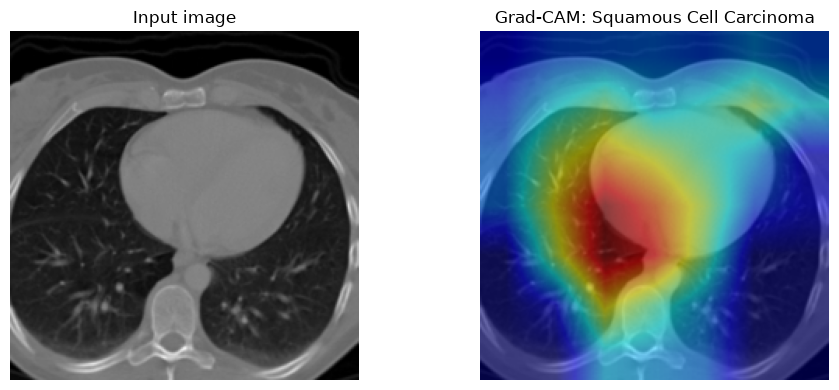

In [18]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

sample_path = test_df.iloc[0]["full_path"]
with Image.open(sample_path) as source:
    source = source.convert("RGB")
    display_image = T.Compose([T.Resize(256), T.CenterCrop(IMAGE_SIZE)])(source)
    rgb_image = np.asarray(display_image).astype(np.float32) / 255.0
    input_tensor = eval_transform(source).unsqueeze(0).to(DEVICE)

with torch.inference_mode():
    sample_logits = model(input_tensor)
    sample_prediction = int(sample_logits.argmax(dim=1).item())

target_layers = [model.layer4[-1]]
with GradCAM(model=model, target_layers=target_layers) as cam:
    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=[ClassifierOutputTarget(sample_prediction)]
    )[0]

visualization = show_cam_on_image(rgb_image, grayscale_cam, use_rgb=True)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("Input image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(visualization)
plt.title(f"Grad-CAM: {DISPLAY_NAMES[sample_prediction]}")
plt.axis("off")
plt.tight_layout()
plt.savefig(REPORT_DIR / "gradcam_example.png", dpi=200, bbox_inches="tight")
plt.show()